# Dynamic Trust-Aware Blockchain Framework for Secure Resource Allocation in Cloud Data Centers

Simulation-based implementation of the proposed framework: resource monitoring, behavior analysis,
dynamic trust score (DTS) computation, blockchain trust ledger, and trust-aware VM scheduling.
Benchmarked against two baselines: a classical resource-only **Greedy Best-Fit (GBF)** scheduler
(the well-known Best-Fit / Modified Best-Fit Decreasing family of heuristics used by default in
systems such as OpenStack Nova and Kubernetes) and a **static trust-based** scheduler that computes
trust once and never updates it, representing the staleness limitation of prior trust-based work.

In [1]:
import numpy as np
import pandas as pd
import hashlib
import json
import sys
import time
from collections import deque
import matplotlib.pyplot as plt
import matplotlib as mpl

SEED = 42
rng_global = np.random.default_rng(SEED)
pd.set_option('display.precision', 4)

PALETTE = {'gbf': '#7F7F7F', 'static_trust': '#FF7F0E', 'proposed': '#1F77B4'}
STRATEGY_LABELS = {'gbf': 'Greedy Best-Fit (Classical, Resource-Only)',
                    'static_trust': 'Static Trust-Based Scheduler',
                    'proposed': 'Proposed Dynamic Trust + Blockchain'}
MAL_COLOR, TRUST_COLOR = '#D62728', '#2CA02C'
NEUTRAL_GRAY, DARK_TEXT = '#7F7F7F', '#2B2B2B'

mpl.rcParams.update({
    'figure.dpi': 150,
    'savefig.dpi': 300,
    'figure.facecolor': 'white',
    'axes.facecolor': 'white',
    'savefig.facecolor': 'white',
    'font.family': 'serif',
    'font.serif': ['Times New Roman', 'DejaVu Serif'],
    'font.size': 11,
    'text.color': '#2B2B2B',
    'axes.titlesize': 12,
    'axes.titleweight': 'bold',
    'axes.titlecolor': '#2B2B2B',
    'axes.labelsize': 11,
    'axes.labelcolor': '#2B2B2B',
    'axes.edgecolor': '#333333',
    'axes.linewidth': 1.0,
    'axes.grid': True,
    'grid.color': '#EAEAEA',
    'grid.linewidth': 0.7,
    'grid.alpha': 1.0,
    'legend.fontsize': 9,
    'legend.frameon': False,
    'legend.labelcolor': '#2B2B2B',
    'xtick.color': '#2B2B2B',
    'ytick.color': '#2B2B2B',
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'lines.linewidth': 1.8,
    'patch.edgecolor': '#333333',
    'savefig.bbox': 'tight',
})

## 1. Configuration



In [2]:
N_NODES = 500
MALICIOUS_RATIO = 0.25
T_INTERVALS = 1000
N_RUNS = 5
VM_PER_INTERVAL = 200
TRUST_THRESHOLD = 0.70
HISTORY_WINDOW = 10
CPU_CAPACITY = 100.0
P_IDLE, P_MAX = 100.0, 250.0
VM_CPU_LOW, VM_CPU_HIGH = 5, 20

## 2. Trust-Parameter Weight Derivation (AHP)

Rather than assigning weights to the six trust parameters (CPU, Memory, Network, Migration
reliability, SLA compliance, Abnormal reporting) heuristically, weights are derived using the
Analytic Hierarchy Process (AHP) from a pairwise comparison matrix, and validated via the
consistency ratio (CR).

In [3]:
AHP_MATRIX = np.array([
    [1,   2,   2,   2,   1,   2],
    [1/2, 1,   1,   1,   1/2, 1],
    [1/2, 1,   1,   1,   1/2, 1],
    [1/2, 1,   1,   1,   1/2, 1],
    [1,   2,   2,   2,   1,   2],
    [1/2, 1,   1,   1,   1/2, 1],
])
PARAM_NAMES = ['CPU', 'Memory', 'Network', 'Migration', 'SLA', 'Abnormality']

def ahp_weights(matrix):
    col_sum = matrix.sum(axis=0)
    norm = matrix / col_sum
    w = norm.mean(axis=1)
    lam_max = (matrix @ w / w).mean()
    n = matrix.shape[0]
    CI = (lam_max - n) / (n - 1)
    RI_TABLE = {1: 0, 2: 0, 3: 0.58, 4: 0.9, 5: 1.12, 6: 1.24, 7: 1.32, 8: 1.41}
    CR = CI / RI_TABLE[n] if RI_TABLE[n] > 0 else 0.0
    return w, CR

W, CR = ahp_weights(AHP_MATRIX)
pd.DataFrame({'Parameter': PARAM_NAMES, 'Weight': np.round(W, 4)})

,Parameter,Weight
0,CPU,0.250
1,Memory,0.125
2,Network,0.125
3,Migration,0.125
4,SLA,0.250
5,Abnormality,0.125


In [4]:
assert CR < 0.10, "AHP pairwise matrix is inconsistent (CR >= 0.10)"
print(f"Consistency Ratio (CR) = {CR:.4f}  (acceptable, CR < 0.10)")

Consistency Ratio (CR) = 0.0000  (acceptable, CR < 0.10)


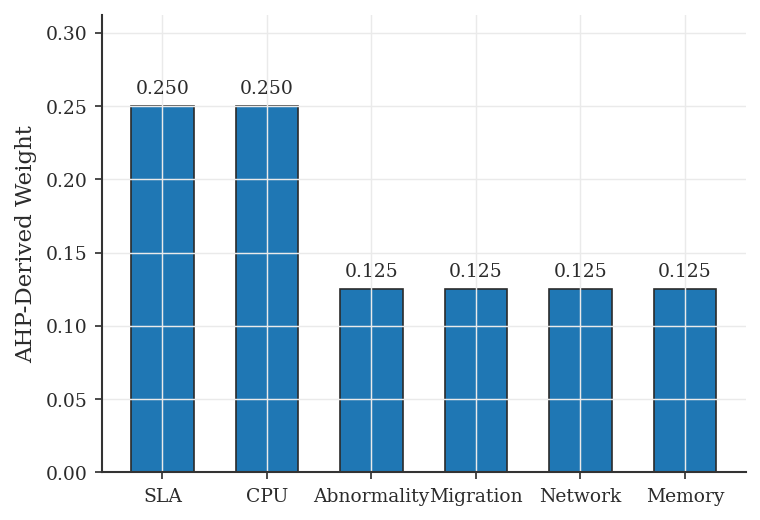

In [5]:
fig, ax = plt.subplots(figsize=(5.2, 3.6))
order = np.argsort(W)[::-1]
bars = ax.bar(np.array(PARAM_NAMES)[order], W[order], color='#1F77B4', width=0.6, edgecolor='#2B2B2B', linewidth=0.8)
for b, val in zip(bars, W[order]):
    ax.text(b.get_x() + b.get_width() / 2, val + 0.006, f'{val:.3f}', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('AHP-Derived Weight')
ax.set_ylim(0, max(W) * 1.25)
plt.tight_layout()
plt.savefig('/kaggle/working/fig_ahp_weights.png', dpi=300)
plt.show()

## 3. Cloud Node Model and Resource Monitoring (Algorithm 1)

Nodes are heterogeneous (General / Compute-optimized / Memory-optimized profiles), and
malicious nodes follow an **on-off ("trust whitewashing") attack pattern**: they behave
honestly for part of each cycle to rebuild trust, then misreport aggressively for the
remainder.

In [6]:
class CloudNode:
    def __init__(self, node_id, is_malicious, base_cpu, base_bw, mem_corr, phase, node_type='General'):
        self.id = node_id
        self.is_malicious = is_malicious
        self.base_cpu = base_cpu
        self.base_bw = base_bw
        self.mem_corr = mem_corr
        self.phase = phase
        self.node_type = node_type
        self.cpu_disc_hist = deque([0.0] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        self.mem_disc_hist = deque([0.0] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        self.bw_disc_hist = deque([0.0] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        self.migration_hist = deque([1] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        self.sla_hist = deque([1] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)

def reset_node_histories(nodes):
    """Re-initializes each node's rolling trust-history state. Called once at the start
    of every strategy's pass over a shared environment so that no history leaks between
    strategies -- each strategy starts from the same blank slate."""
    for n in nodes:
        n.cpu_disc_hist = deque([0.0] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        n.mem_disc_hist = deque([0.0] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        n.bw_disc_hist = deque([0.0] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        n.migration_hist = deque([1] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)
        n.sla_hist = deque([1] * HISTORY_WINDOW, maxlen=HISTORY_WINDOW)

def initialize_nodes(n_nodes, malicious_ratio, rng):
    """Base workload intensities are drawn from a right-skewed Beta distribution and
    each node is assigned a random diurnal phase offset, a CPU-memory correlation
    coefficient, and a resource profile (General / Compute / Memory), reproducing
    realistic, heterogeneous cloud-traffic characteristics rather than uniform synthetic
    load."""
    n_mal = int(round(n_nodes * malicious_ratio))
    labels = np.array([True] * n_mal + [False] * (n_nodes - n_mal))
    rng.shuffle(labels)
    nodes = []
    node_types = ['General', 'Compute', 'Memory']
    for i in range(n_nodes):
        base_cpu = np.clip(rng.beta(2.0, 5.0) * 90 + 5, 1, 99)
        base_bw = np.clip(rng.beta(1.5, 6.0) * 80 + 5, 1, 95)
        mem_corr = rng.uniform(0.6, 0.9)
        phase = rng.uniform(0, 2 * np.pi)
        n_type = rng.choice(node_types, p=[0.6, 0.2, 0.2])
        nodes.append(CloudNode(i, bool(labels[i]), base_cpu, base_bw, mem_corr, phase, n_type))
    return nodes

In [7]:
def monitor_resources(nodes, t, rng):
    """Algorithm 1: Resource Monitoring. Utilization combines a right-skewed base load,
    a diurnal (daily-cycle) component, and occasional bursty spikes. Compute/Memory-profile
    nodes decouple CPU and memory demand accordingly. Malicious nodes follow an on-off
    whitewashing cycle: honest for the first 60% of each 50-interval window, actively
    misreporting for the remaining 40%, then repeating."""
    report = {}
    for n in nodes:
        if n.is_malicious:
            cycle_pos = t % 50
            is_currently_lying = cycle_pos > 30
        else:
            is_currently_lying = False

        diurnal = 12 * np.sin(2 * np.pi * t / T_INTERVALS + n.phase)
        burst = rng.uniform(15, 35) if rng.random() < 0.06 else 0.0

        if n.node_type == 'Compute':
            actual_cpu = np.clip(n.base_cpu + diurnal + burst + rng.normal(0, 4), 1, 100)
            actual_mem = np.clip(n.base_cpu * 0.4 + rng.normal(0, 2), 1, 100)
        elif n.node_type == 'Memory':
            actual_cpu = np.clip(n.base_cpu * 0.4 + rng.normal(0, 2), 1, 100)
            actual_mem = np.clip(n.base_cpu * n.mem_corr + diurnal + burst + rng.normal(0, 4), 1, 100)
        else:
            actual_cpu = np.clip(n.base_cpu + diurnal + burst + rng.normal(0, 3), 1, 100)
            actual_mem = np.clip(n.base_cpu * n.mem_corr + 0.8 * diurnal + 0.6 * burst + rng.normal(0, 3), 1, 100)
        actual_bw = np.clip(n.base_bw + 0.5 * diurnal + 0.4 * burst + rng.normal(0, 4), 1, 100)

        migration_ok = rng.random() > (0.35 if n.is_malicious and is_currently_lying else 0.05)
        sla_ok = rng.random() > (0.40 if n.is_malicious and is_currently_lying else 0.06)

        if n.is_malicious and is_currently_lying:
            reported_cpu = np.clip(actual_cpu - rng.uniform(20, 45), 0, 100)
            reported_mem = np.clip(actual_mem - rng.uniform(20, 45), 0, 100)
            reported_bw = np.clip(actual_bw - rng.uniform(10, 30), 0, 100)
        else:
            reported_cpu = np.clip(actual_cpu + rng.normal(0, 1.5), 0, 100)
            reported_mem = np.clip(actual_mem + rng.normal(0, 1.5), 0, 100)
            reported_bw = np.clip(actual_bw + rng.normal(0, 1.5), 0, 100)
        report[n.id] = dict(actual_cpu=actual_cpu, actual_mem=actual_mem, actual_bw=actual_bw,
                             reported_cpu=reported_cpu, reported_mem=reported_mem,
                             reported_bw=reported_bw, migration_ok=migration_ok, sla_ok=sla_ok)
    return report

## 4. Behavior Analysis and Dynamic Trust Score (Algorithm 2)

Discrepancies between actual and reported values feed a rolling-window consistency score per
parameter. The Dynamic Trust Score (DTS) is the AHP-derived weighted sum:

$$DTS_i = \sum_{k=1}^{6} w_k P_k, \qquad \sum_k w_k = 1$$

In [8]:
def analyze_behavior(nodes, monitoring_report, sensitivity=2.0):
    """Algorithm 2 (part A): Behaviour Analysis - per-parameter consistency scores."""
    scores = {}
    for n in nodes:
        r = monitoring_report[n.id]
        d_cpu = abs(r['actual_cpu'] - r['reported_cpu']) / 100.0
        d_mem = abs(r['actual_mem'] - r['reported_mem']) / 100.0
        d_bw = abs(r['actual_bw'] - r['reported_bw']) / 100.0
        n.cpu_disc_hist.append(d_cpu)
        n.mem_disc_hist.append(d_mem)
        n.bw_disc_hist.append(d_bw)
        n.migration_hist.append(1 if r['migration_ok'] else 0)
        n.sla_hist.append(1 if r['sla_ok'] else 0)
        C = np.clip(1 - np.mean(n.cpu_disc_hist) * sensitivity, 0, 1)
        M = np.clip(1 - np.mean(n.mem_disc_hist) * sensitivity, 0, 1)
        N = np.clip(1 - np.mean(n.bw_disc_hist) * sensitivity, 0, 1)
        V = np.mean(n.migration_hist)
        S = np.mean(n.sla_hist)
        mean_disc = (np.mean(n.cpu_disc_hist) + np.mean(n.mem_disc_hist) + np.mean(n.bw_disc_hist)) / 3.0
        A = np.clip(1 - mean_disc * sensitivity, 0, 1)
        scores[n.id] = dict(C=C, M=M, N=N, V=V, S=S, A=A)
    return scores

def compute_trust_scores(behavior_scores, weights):
    """Algorithm 2 (part B): Dynamic Trust Score Computation."""
    trust = {}
    for nid, s in behavior_scores.items():
        dts = (weights[0] * s['C'] + weights[1] * s['M'] + weights[2] * s['N'] +
               weights[3] * s['V'] + weights[4] * s['S'] + weights[5] * s['A'])
        trust[nid] = float(np.clip(dts, 0, 1))
    return trust

def classify_trust(score):
    if score >= 0.85: return 'Highly Trusted'
    if score >= 0.70: return 'Trusted'
    if score >= 0.50: return 'Suspicious'
    return 'Malicious'

## 5. Blockchain Trust Ledger (Algorithm 3)

In [9]:
class Block:
    def __init__(self, index, timestamp, records, events, previous_hash):
        self.index = index
        self.timestamp = timestamp
        self.records = records
        self.events = events
        self.previous_hash = previous_hash
        self.hash = self.compute_hash()

    def compute_hash(self):
        payload = json.dumps({'index': self.index, 'timestamp': self.timestamp,
                               'records': self.records, 'events': self.events,
                               'previous_hash': self.previous_hash}, sort_keys=True)
        return hashlib.sha256(payload.encode()).hexdigest()

    def size_bytes(self):
        return sys.getsizeof(json.dumps({'records': self.records, 'events': self.events}))

class TrustBlockchain:
    """Algorithm 3: Blockchain Trust Update. Stores only trust scores and security
    events per interval, never raw monitoring data, to keep the ledger lightweight."""
    def __init__(self):
        self.chain = [Block(0, 0.0, {}, [], '0' * 64)]

    def add_block(self, t, trust_scores, threshold):
        events = [f"node_{nid}_flagged" for nid, s in trust_scores.items() if s < threshold]
        records = {str(nid): round(s, 4) for nid, s in trust_scores.items()}
        block = Block(len(self.chain), float(t), records, events, self.chain[-1].hash)
        self.chain.append(block)
        return block

    def is_valid(self):
        for i in range(1, len(self.chain)):
            if self.chain[i].previous_hash != self.chain[i - 1].hash:
                return False
            if self.chain[i].hash != self.chain[i].compute_hash():
                return False
        return True

def raw_monitoring_size(monitoring_report):
    return sys.getsizeof(json.dumps(monitoring_report))

## 6. Trust-Aware Resource Allocation (Algorithm 4) and Baseline Schedulers



In [10]:
def greedy_best_fit_allocate(nodes_state, vm_requests):
    """Classical resource-only Best-Fit (BF) scheduling: choose the feasible node that
    leaves the least leftover capacity after placement. This is the same rule underlying
    Best-Fit-Decreasing bin-packing (Coffman, Garey and Johnson) and its cloud-specific
    variant Modified Best-Fit Decreasing (MBFD; Beloglazov and Buyya, 2012), and
    approximates the default resource-driven placement policy of systems such as
    OpenStack Nova's filter scheduler and Kubernetes' default scheduler -- none of which
    considers node trust or security posture. It never looks at trust scores."""
    allocations = []
    for vm_cpu in vm_requests:
        candidates = [nid for nid, st in nodes_state.items() if st['free_cpu'] >= vm_cpu]
        if not candidates:
            allocations.append(None); continue
        chosen = min(candidates, key=lambda nid: nodes_state[nid]['free_cpu'] - vm_cpu)
        nodes_state[chosen]['free_cpu'] -= vm_cpu
        allocations.append(chosen)
    return allocations

def trust_aware_allocate(nodes_state, vm_requests, trust_scores, threshold):
    """Algorithm 4: identical best-fit rule to greedy_best_fit_allocate, with candidates
    additionally restricted to nodes whose trust score meets the threshold."""
    allocations = []
    for vm_cpu in vm_requests:
        candidates = [nid for nid, st in nodes_state.items()
                      if st['free_cpu'] >= vm_cpu and trust_scores.get(nid, 0) >= threshold]
        if not candidates:
            allocations.append(None); continue
        chosen = min(candidates, key=lambda nid: nodes_state[nid]['free_cpu'] - vm_cpu)
        nodes_state[chosen]['free_cpu'] -= vm_cpu
        allocations.append(chosen)
    return allocations

## 7. Continuous Monitoring-Trust-Allocation Loop (Algorithm 6)



In [11]:
def power_model(utilization_fraction):
    return P_IDLE + (P_MAX - P_IDLE) * utilization_fraction

def sla_violation_trial(node_is_malicious, rng):
    return rng.random() < (0.35 if node_is_malicious else 0.03)

def generate_vm_requests(t, rng, base_rate=VM_PER_INTERVAL):
    """VM arrival intensity follows a diurnal (business-hours) cycle and request sizes
    follow a heavy-tailed log-normal distribution, reflecting the bursty arrival process
    and the many-small/few-large VM size mix widely reported for cloud workloads, rather
    than a constant arrival rate with uniformly-sized requests."""
    diurnal_factor = 0.5 + 0.5 * np.sin(2 * np.pi * t / T_INTERVALS - np.pi / 2)
    rate = base_rate * (0.5 + diurnal_factor)
    n_requests = max(int(rng.poisson(rate)), 1)
    sizes = np.clip(rng.lognormal(mean=np.log(8.0), sigma=0.6, size=n_requests), VM_CPU_LOW, VM_CPU_HIGH)
    return list(sizes)

def build_environment(env_seed, n_nodes=N_NODES, malicious_ratio=MALICIOUS_RATIO,
                       t_intervals=T_INTERVALS, vm_per_interval=VM_PER_INTERVAL):
    """Pre-generates one shared environment (nodes, monitoring telemetry for every
    interval, VM arrival sequence) that will be replayed identically for every strategy."""
    env_rng = np.random.default_rng(env_seed)
    nodes = initialize_nodes(n_nodes, malicious_ratio, env_rng)
    ground_truth_malicious = {n.id: n.is_malicious for n in nodes}
    monitoring_reports, vm_requests_seq = [], []
    for t in range(t_intervals):
        monitoring_reports.append(monitor_resources(nodes, t, env_rng))
        vm_requests_seq.append(generate_vm_requests(t, env_rng, vm_per_interval))
    reset_node_histories(nodes)
    return dict(nodes=nodes, ground_truth_malicious=ground_truth_malicious,
                monitoring_reports=monitoring_reports, vm_requests_seq=vm_requests_seq)

def run_simulation(strategy, environment, outcome_seed, t_intervals=T_INTERVALS,
                    threshold=TRUST_THRESHOLD, weights=W):
    nodes = environment['nodes']
    ground_truth_malicious = environment['ground_truth_malicious']
    monitoring_reports = environment['monitoring_reports']
    vm_requests_seq = environment['vm_requests_seq']
    reset_node_histories(nodes)
    outcome_rng = np.random.default_rng(outcome_seed)
    blockchain = TrustBlockchain()
    static_trust = None
    log = []

    for t in range(t_intervals):
        monitoring_report = monitoring_reports[t]

        t0 = time.perf_counter()
        behavior_scores = analyze_behavior(nodes, monitoring_report)
        trust_scores = compute_trust_scores(behavior_scores, weights)
        trust_compute_time = time.perf_counter() - t0

        if strategy == 'static_trust' and static_trust is None:
            static_trust = dict(trust_scores)
        active_trust = trust_scores if strategy == 'proposed' else \
                       (static_trust if strategy == 'static_trust' else None)

        nodes_state = {n.id: dict(free_cpu=CPU_CAPACITY - monitoring_report[n.id]['reported_cpu'])
                       for n in nodes}
        vm_requests = vm_requests_seq[t]

        t1 = time.perf_counter()
        if strategy == 'gbf':
            allocations = greedy_best_fit_allocate(nodes_state, vm_requests)
        else:
            allocations = trust_aware_allocate(nodes_state, vm_requests, active_trust, threshold)
        scheduling_time = time.perf_counter() - t1

        if strategy == 'proposed':
            block = blockchain.add_block(t, trust_scores, threshold)
            bc_overhead = block.size_bytes()
        else:
            bc_overhead = 0.0

        allocated = [a for a in allocations if a is not None]
        throughput = len(allocated)
        sla_violations = sum(sla_violation_trial(ground_truth_malicious[nid], outcome_rng) for nid in allocated)
        utils = [(CPU_CAPACITY - nodes_state[nid]['free_cpu']) / CPU_CAPACITY for nid in nodes_state]
        resource_utilization = float(np.mean(utils))
        energy = float(np.sum([power_model(u) for u in utils]))

        if strategy in ('proposed', 'static_trust'):
            n_malicious = sum(ground_truth_malicious.values())
            flagged = sum(1 for nid, s in active_trust.items()
                          if s < threshold and ground_truth_malicious[nid])
            detection_rate = flagged / n_malicious if n_malicious > 0 else np.nan
        else:
            detection_rate = np.nan

        if strategy in ('proposed', 'static_trust'):
            mal_trust = np.mean([active_trust[nid] for nid in active_trust if ground_truth_malicious[nid]])
            trusted_trust = np.mean([active_trust[nid] for nid in active_trust if not ground_truth_malicious[nid]])
        else:
            mal_trust, trusted_trust = np.nan, np.nan

        log.append(dict(t=t, strategy=strategy, throughput=throughput,
                         sla_violations=sla_violations, resource_utilization=resource_utilization,
                         energy=energy, scheduling_time=scheduling_time,
                         trust_compute_time=trust_compute_time if strategy != 'gbf' else np.nan,
                         blockchain_overhead=bc_overhead, malicious_detection_rate=detection_rate,
                         avg_trust_malicious=mal_trust, avg_trust_trusted=trusted_trust))

    final_trust = trust_scores
    return pd.DataFrame(log), final_trust, ground_truth_malicious, blockchain

## 8. Comparative Evaluation: GBF vs. Static Trust-Based vs. Proposed Framework

In [12]:
STRATEGIES = ['gbf', 'static_trust', 'proposed']
ENV_SEED_BASE = 20260
OUTCOME_SEED_BASE = 77000
all_runs, final_trust_records, blockchain_ref = [], [], None

for run in range(N_RUNS):
    environment = build_environment(ENV_SEED_BASE + run)
    for strat in STRATEGIES:
        df, final_trust, gt_mal, bc = run_simulation(strat, environment, outcome_seed=OUTCOME_SEED_BASE + run)
        df['run'] = run
        all_runs.append(df)
        if strat == 'proposed':
            final_trust_records.append((run, final_trust, gt_mal))
            blockchain_ref = bc

results = pd.concat(all_runs, ignore_index=True)
results.head()

,t,strategy,throughput,sla_violations,resource_utilization,energy,scheduling_time,trust_compute_time,blockchain_overhead,malicious_detection_rate,avg_trust_malicious,avg_trust_trusted,run
0,0,gbf,100,15,0.2914,71855.8822,0.0124,NaN,0.0,NaN,NaN,NaN,0
1,1,gbf,84,6,0.2874,71553.9829,0.0104,NaN,0.0,NaN,NaN,NaN,0
2,2,gbf,75,3,0.2857,71429.7119,0.0091,NaN,0.0,NaN,NaN,NaN,0
3,3,gbf,104,7,0.2957,72180.8187,0.0124,NaN,0.0,NaN,NaN,NaN,0
4,4,gbf,109,5,0.2932,71987.4958,0.0138,NaN,0.0,NaN,NaN,NaN,0


In [13]:
summary = results.groupby('strategy').agg(
    throughput_mean=('throughput', 'mean'),
    sla_violations_mean=('sla_violations', 'mean'),
    resource_utilization_mean=('resource_utilization', 'mean'),
    energy_mean=('energy', 'mean'),
    scheduling_time_ms=('scheduling_time', lambda x: x.mean() * 1000),
    trust_compute_time_ms=('trust_compute_time', lambda x: x.mean() * 1000),
    blockchain_overhead_bytes=('blockchain_overhead', 'mean'),
    malicious_detection_rate=('malicious_detection_rate', 'mean'),
).round(4)
summary

,throughput_mean,sla_violations_mean,resource_utilization_mean,energy_mean,scheduling_time_ms,trust_compute_time_ms,blockchain_overhead_bytes,malicious_detection_rate
strategy,,,,,,,,
gbf,200.013,16.7980,0.2961,72211.2032,22.8084,NaN,0.000,NaN
proposed,200.013,15.3226,0.2961,72211.2032,25.2363,49.6498,7984.959,0.2356
static_trust,200.013,16.7980,0.2961,72211.2032,26.3379,49.4969,0.000,0.0000


## 9. Malicious Node Detection: Confusion Matrix (Proposed Framework)



In [14]:
y_true_all, y_pred_all = [], []
for run_id, final_trust, gt_mal in final_trust_records:
    for nid in sorted(gt_mal):
        y_true_all.append(gt_mal[nid])
        y_pred_all.append(final_trust[nid] < TRUST_THRESHOLD)
y_true = np.array(y_true_all)
y_pred = np.array(y_pred_all)

TP = int(np.sum(y_true & y_pred))
FN = int(np.sum(y_true & ~y_pred))
FP = int(np.sum(~y_true & y_pred))
TN = int(np.sum(~y_true & ~y_pred))

precision = TP / (TP + FP) if (TP + FP) > 0 else np.nan
recall = TP / (TP + FN) if (TP + FN) > 0 else np.nan
f1 = 2 * precision * recall / (precision + recall) if precision and recall else np.nan

confusion = pd.DataFrame([[TP, FN], [FP, TN]],
                          index=['Actual Malicious', 'Actual Trusted'],
                          columns=['Predicted Malicious', 'Predicted Trusted'])
print(confusion)
print(f"\nFinal-snapshot (pooled across {N_RUNS} runs): Precision={precision:.3f}  Recall={recall:.3f}  F1={f1:.3f}")
print(f"Whole-run average detection rate (from summary table): {summary.loc['proposed', 'malicious_detection_rate']:.3f}")

                  Predicted Malicious  Predicted Trusted
Actual Malicious                  506                119
Actual Trusted                      0               1875

Final-snapshot (pooled across 5 runs): Precision=1.000  Recall=0.810  F1=0.895
Whole-run average detection rate (from summary table): 0.236


## 10. Visualization



### 10.1 Synthetic Workload Realism Check

Node CPU utilization combines a right-skewed Beta(2,5) base load, a diurnal (business-hours)
demand cycle, and Poisson-triggered bursts. VM arrivals follow a diurnal-intensity Poisson
process, and request sizes follow a log-normal distribution. Together these reproduce the
skewed load distribution, day/night demand cycle, bursty traffic, and many-small/few-large
request-size mix characteristic of real cloud workloads, rather than uniform synthetic load
and fixed-rate arrivals. 

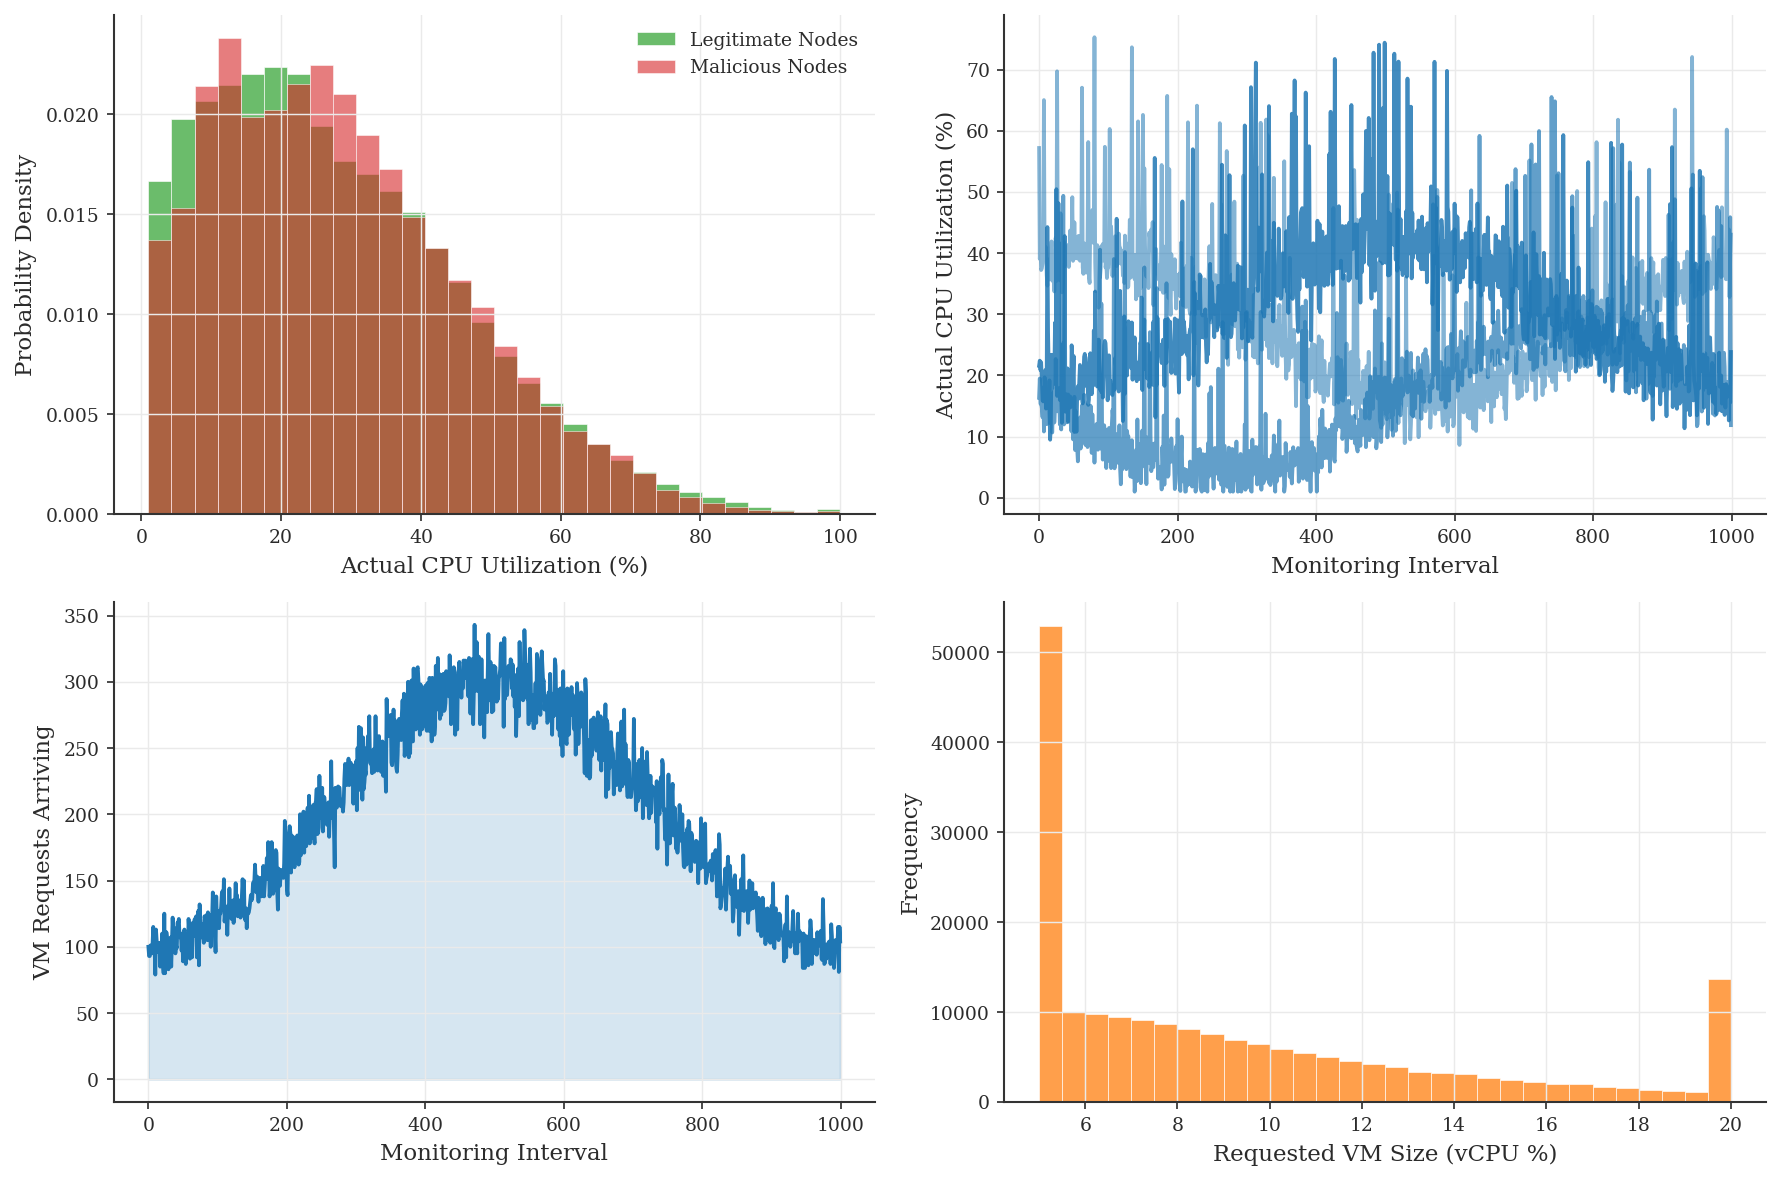

In [15]:
rng_check = np.random.default_rng(123)
nodes_check = initialize_nodes(N_NODES, MALICIOUS_RATIO, rng_check)
trace_records, vm_arrival_counts, vm_sizes_all = [], [], []
for t in range(T_INTERVALS):
    rep = monitor_resources(nodes_check, t, rng_check)
    for n in nodes_check:
        trace_records.append(dict(t=t, node=n.id, malicious=n.is_malicious,
                                   actual_cpu=rep[n.id]['actual_cpu'], actual_mem=rep[n.id]['actual_mem']))
    vm_batch = generate_vm_requests(t, rng_check)
    vm_arrival_counts.append(dict(t=t, n_requests=len(vm_batch)))
    vm_sizes_all.extend(vm_batch)
trace_df = pd.DataFrame(trace_records)
arrivals_df = pd.DataFrame(vm_arrival_counts)

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

axes[0, 0].hist(trace_df.loc[~trace_df['malicious'], 'actual_cpu'], bins=30, color=TRUST_COLOR,
                alpha=0.7, density=True, label='Legitimate Nodes', edgecolor='white', linewidth=0.4)
axes[0, 0].hist(trace_df.loc[trace_df['malicious'], 'actual_cpu'], bins=30, color=MAL_COLOR,
                alpha=0.6, density=True, label='Malicious Nodes', edgecolor='white', linewidth=0.4)
axes[0, 0].set_xlabel('Actual CPU Utilization (%)')
axes[0, 0].set_ylabel('Probability Density')
axes[0, 0].legend()

sample_nodes = [n.id for n in nodes_check if not n.is_malicious][:3]
for i, nid in enumerate(sample_nodes):
    sub = trace_df[trace_df['node'] == nid]
    axes[0, 1].plot(sub['t'], sub['actual_cpu'], color=PALETTE['proposed'], alpha=0.55 + 0.15 * i,
                     label=f'Node {nid}' if i == 0 else None)
axes[0, 1].set_xlabel('Monitoring Interval')
axes[0, 1].set_ylabel('Actual CPU Utilization (%)')

axes[1, 0].plot(arrivals_df['t'], arrivals_df['n_requests'], color=PALETTE['proposed'])
axes[1, 0].fill_between(arrivals_df['t'], 0, arrivals_df['n_requests'], color=PALETTE['proposed'], alpha=0.18)
axes[1, 0].set_xlabel('Monitoring Interval')
axes[1, 0].set_ylabel('VM Requests Arriving')

axes[1, 1].hist(vm_sizes_all, bins=30, color=PALETTE['static_trust'], alpha=0.75, edgecolor='white', linewidth=0.4)
axes[1, 1].set_xlabel('Requested VM Size (vCPU %)')
axes[1, 1].set_ylabel('Frequency')

plt.tight_layout()
plt.savefig('/kaggle/working/fig_workload_and_traffic_realism.png', dpi=300)
plt.show()

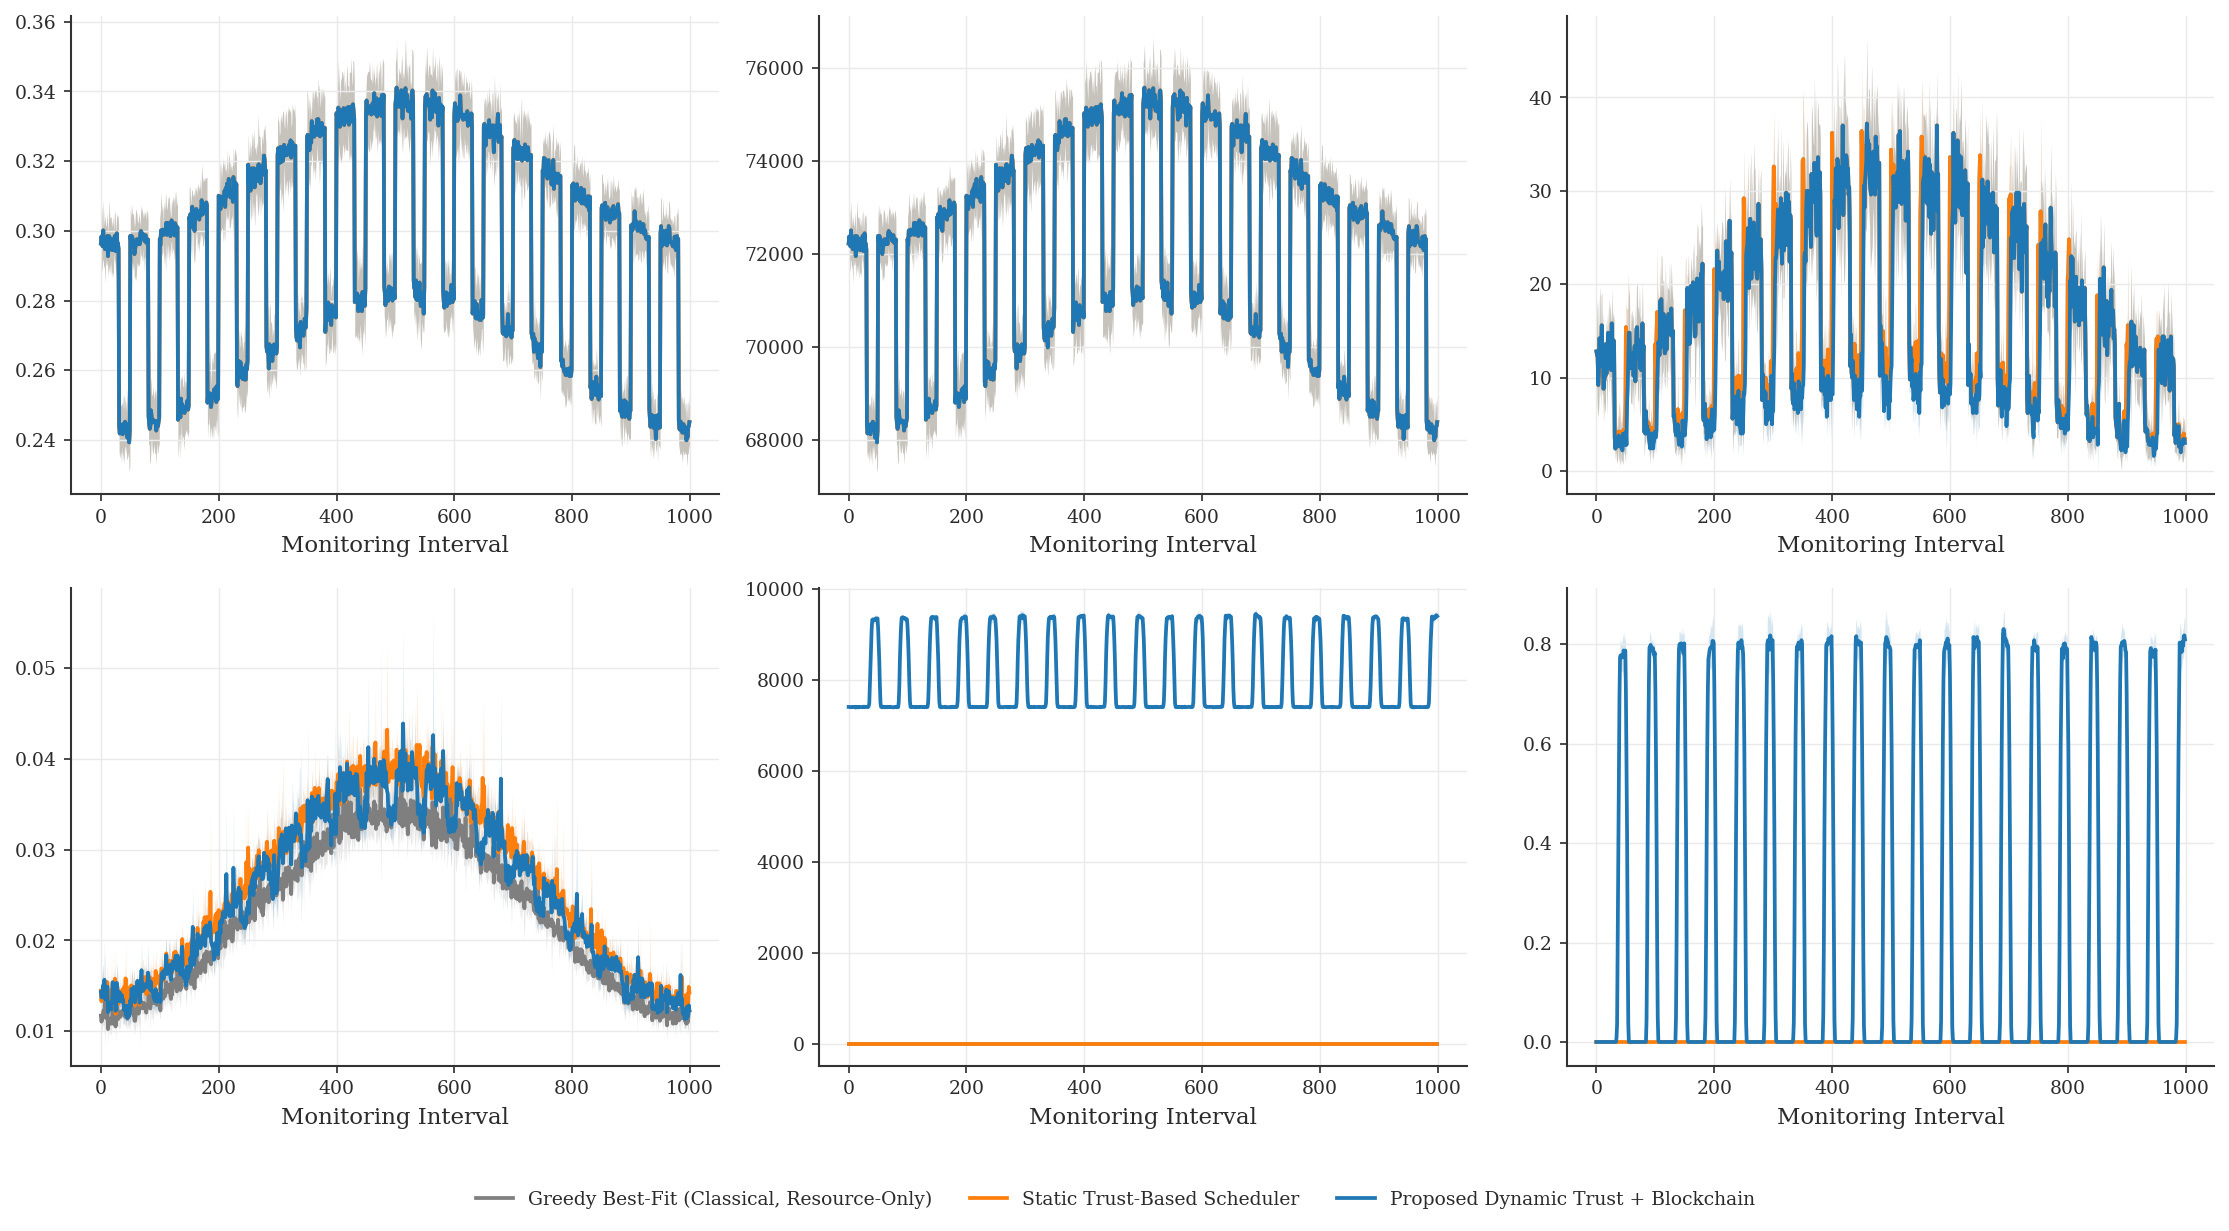

In [16]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
metrics = ['resource_utilization', 'energy', 'sla_violations',
           'scheduling_time', 'blockchain_overhead', 'malicious_detection_rate']
titles = ['Resource Utilization', 'Energy Consumption (W)', 'SLA Violations per Interval',
          'Scheduling Time (s)', 'Blockchain / Storage Overhead (bytes)', 'Malicious Node Detection Rate']

for ax, metric, title in zip(axes.flat, metrics, titles):
    grouped = results.groupby(['strategy', 't'])[metric].agg(['mean', 'std']).reset_index()
    for strat in STRATEGIES:
        sub = grouped[grouped['strategy'] == strat]
        if sub['mean'].isna().all():
            continue
        ax.plot(sub['t'], sub['mean'], label=STRATEGY_LABELS[strat], color=PALETTE[strat])
        ax.fill_between(sub['t'], sub['mean'] - sub['std'], sub['mean'] + sub['std'],
                         color=PALETTE[strat], alpha=0.18, linewidth=0)
    ax.set_xlabel('Monitoring Interval')

handles, labels = axes.flat[0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=3, bbox_to_anchor=(0.5, -0.03), frameon=False)
plt.tight_layout(rect=[0, 0.03, 1, 1])
plt.savefig('/kaggle/working/fig_comparative_metrics.png', dpi=300)
plt.show()

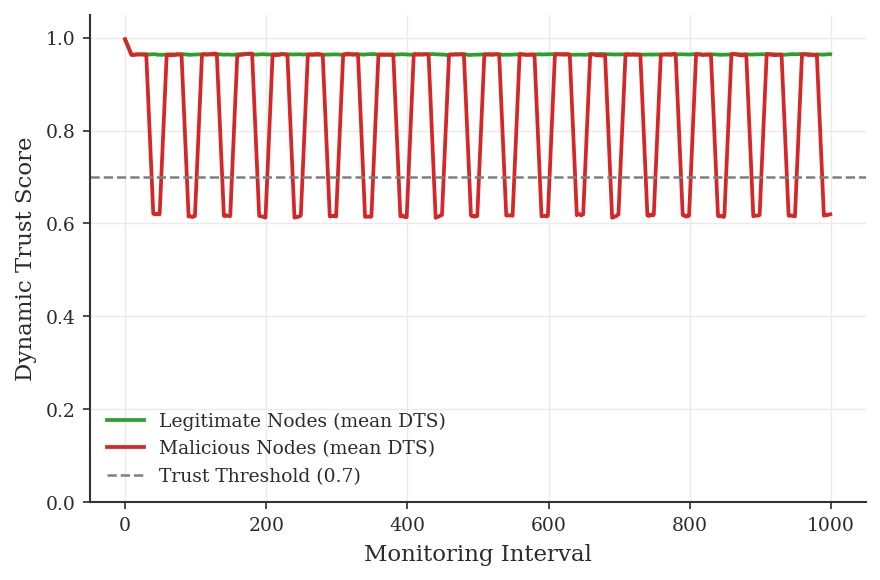

In [17]:
fig, ax = plt.subplots(figsize=(6, 4))
grouped = results.groupby(['strategy', 't'])[['avg_trust_malicious', 'avg_trust_trusted']].mean().reset_index()
sub = grouped[grouped['strategy'] == 'proposed']
ax.plot(sub['t'], sub['avg_trust_trusted'], label='Legitimate Nodes (mean DTS)', color=TRUST_COLOR)
ax.plot(sub['t'], sub['avg_trust_malicious'], label='Malicious Nodes (mean DTS)', color=MAL_COLOR)
ax.axhline(TRUST_THRESHOLD, color=NEUTRAL_GRAY, linestyle='--', linewidth=1.2, label=f'Trust Threshold ({TRUST_THRESHOLD})')
ax.set_xlabel('Monitoring Interval')
ax.set_ylabel('Dynamic Trust Score')
ax.set_ylim(0, 1.05)
ax.legend()
plt.tight_layout()
plt.savefig('/kaggle/working/fig_trust_convergence.png', dpi=300)
plt.show()

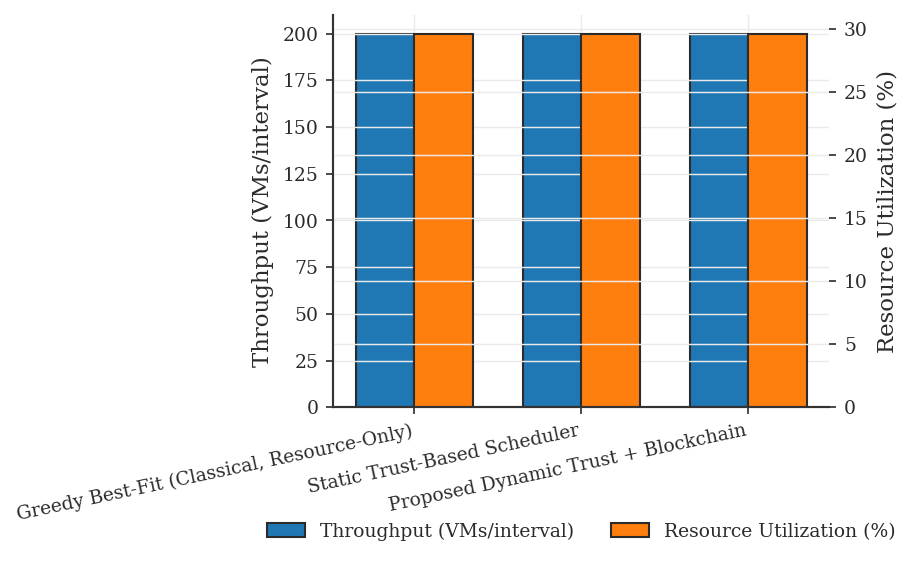

In [18]:
fig, ax = plt.subplots(figsize=(6, 4))
x = np.arange(len(STRATEGIES))
width = 0.35
throughput_vals = [summary.loc[s, 'throughput_mean'] for s in STRATEGIES]
utilization_vals = [summary.loc[s, 'resource_utilization_mean'] * 100 for s in STRATEGIES]
bars1 = ax.bar(x - width / 2, throughput_vals, width, label='Throughput (VMs/interval)', color='#1F77B4', edgecolor='#2B2B2B')
ax2 = ax.twinx()
bars2 = ax2.bar(x + width / 2, utilization_vals, width, label='Resource Utilization (%)', color='#FF7F0E', edgecolor='#2B2B2B')
ax.set_xticks(x)
ax.set_xticklabels([STRATEGY_LABELS[s] for s in STRATEGIES], rotation=12, ha='right')
ax.set_ylabel('Throughput (VMs/interval)')
ax2.set_ylabel('Resource Utilization (%)')
lines = [bars1, bars2]
ax.legend(lines, [l.get_label() for l in lines], loc='upper center', bbox_to_anchor=(0.5, -0.25), ncol=2)
plt.tight_layout()
plt.savefig('/kaggle/working/fig_throughput_utilization.png', dpi=300)
plt.show()

/tmp/ipykernel_23/360511827.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True, labels=[STRATEGY_LABELS[s].replace(' ', '\n') for s in STRATEGIES],
/tmp/ipykernel_23/360511827.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True, labels=[STRATEGY_LABELS[s].replace(' ', '\n') for s in STRATEGIES],
/tmp/ipykernel_23/360511827.py:7: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bp = ax.boxplot(data, patch_artist=True, labels=[STRATEGY_LABELS[s].replace(' ', '\n') for s in STRATEGIES],


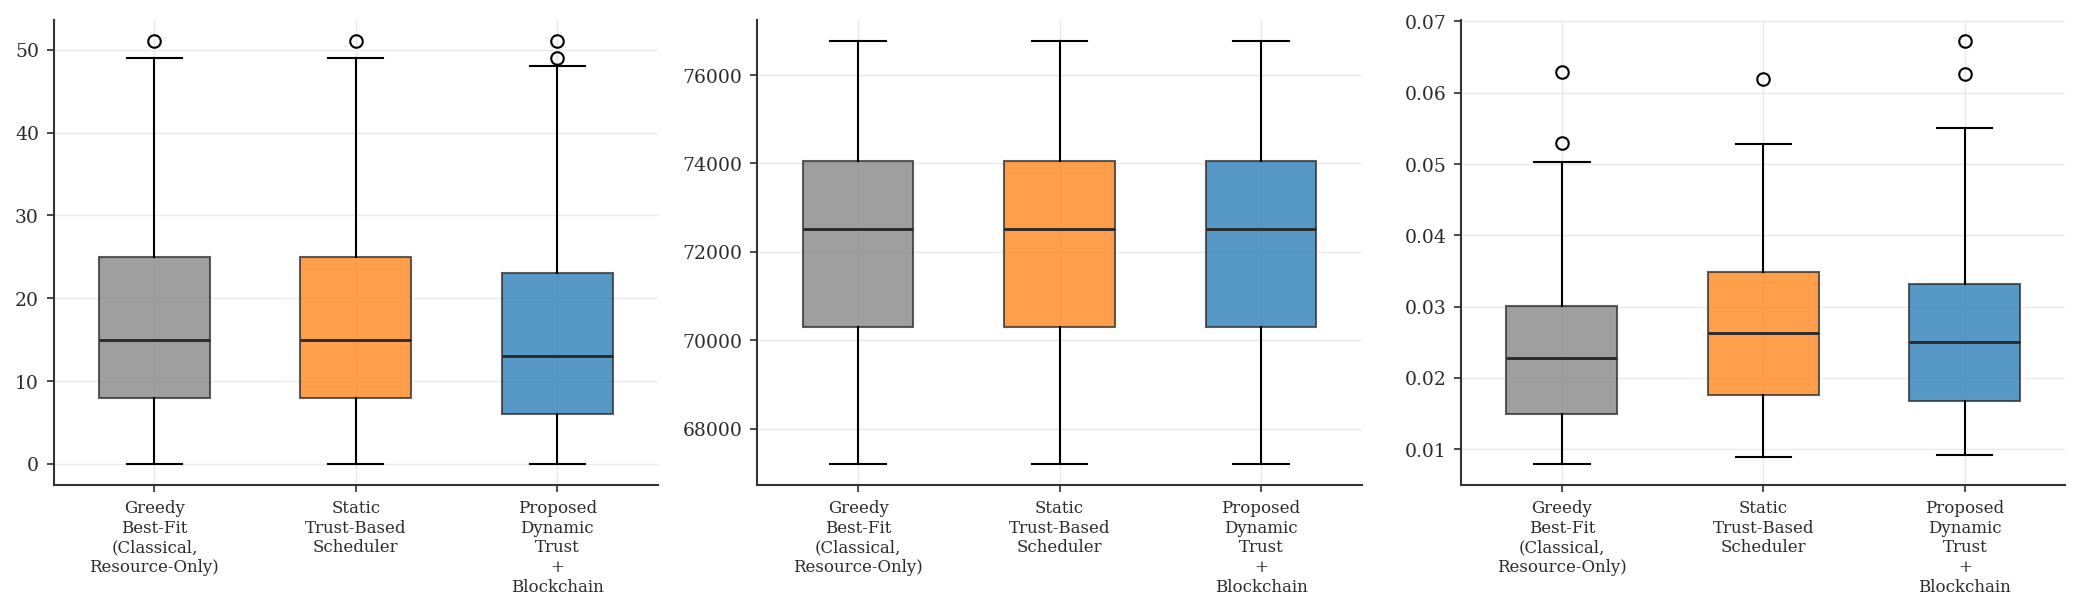

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
box_metrics = ['sla_violations', 'energy', 'scheduling_time']
box_titles = ['SLA Violations Distribution', 'Energy Consumption Distribution', 'Scheduling Time Distribution (s)']

for ax, metric, title in zip(axes, box_metrics, box_titles):
    data = [results[results['strategy'] == s][metric].dropna().values for s in STRATEGIES]
    bp = ax.boxplot(data, patch_artist=True, labels=[STRATEGY_LABELS[s].replace(' ', '\n') for s in STRATEGIES],
                     widths=0.55, medianprops=dict(color='#2B2B2B', linewidth=1.4))
    for patch, strat in zip(bp['boxes'], STRATEGIES):
        patch.set_facecolor(PALETTE[strat])
        patch.set_alpha(0.75)
        patch.set_edgecolor('#2B2B2B')
    ax.tick_params(axis='x', labelsize=8)

plt.tight_layout()
plt.savefig('/kaggle/working/fig_metric_distributions.png', dpi=300)
plt.show()

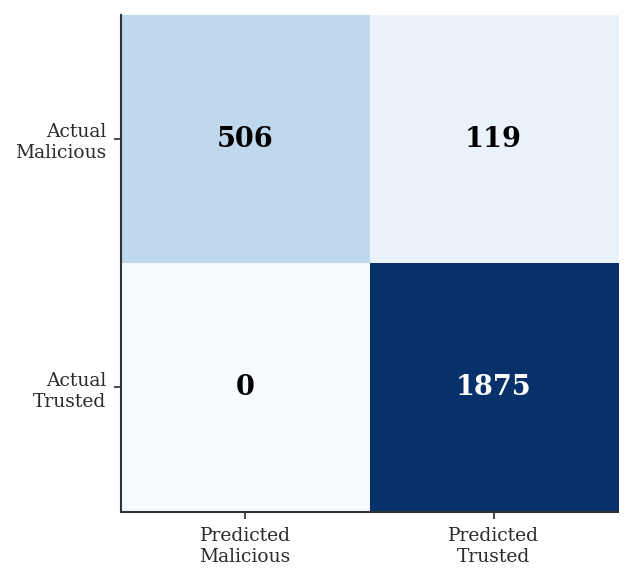

In [20]:
fig, ax = plt.subplots(figsize=(4.5, 4))
cm = confusion.values
im = ax.imshow(cm, cmap='Blues', vmin=0)
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        color = 'white' if cm[i, j] > cm.max() / 2 else 'black'
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color=color, fontsize=13, fontweight='bold')
ax.set_xticks([0, 1]); ax.set_yticks([0, 1])
ax.set_xticklabels(['Predicted\nMalicious', 'Predicted\nTrusted'])
ax.set_yticklabels(['Actual\nMalicious', 'Actual\nTrusted'])
ax.grid(False)
plt.tight_layout()
plt.savefig('/kaggle/working/fig_confusion_matrix.png', dpi=300)
plt.show()

### 10.6 Ledger Storage Design Comparison (Illustrative)

Neither GBF nor the static-trust baseline maintains any persistent security ledger, so their
per-interval storage overhead is genuinely zero -- that reflects the absence of any auditable
security trail in classical schedulers, not a deficiency being penalized here. To make the
benefit of the proposed design explicit, we instead compare the proposed ledger's actual
per-interval footprint (trust scores and flagged events only) against what a **naive
full-telemetry audit log** would cost if an operator wanted the same auditability without
blockchain-style compaction.

In [21]:
naive_full_log_bytes = float(np.mean([raw_monitoring_size(mr) for mr in environment['monitoring_reports']]))
ledger_bytes = float(summary.loc['proposed', 'blockchain_overhead_bytes'])
overhead_comparison = pd.DataFrame({
    'Design': ['Naive Full-Telemetry Audit Log', 'Proposed Blockchain Trust Ledger'],
    'Mean Bytes / Interval': [naive_full_log_bytes, ledger_bytes]})
overhead_comparison

,Design,Mean Bytes / Interval
0,Naive Full-Telemetry Audit Log,123791.155
1,Proposed Blockchain Trust Ledger,7984.959


/tmp/ipykernel_23/2634525840.py:7: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(overhead_comparison['Design'], rotation=10, ha='right')


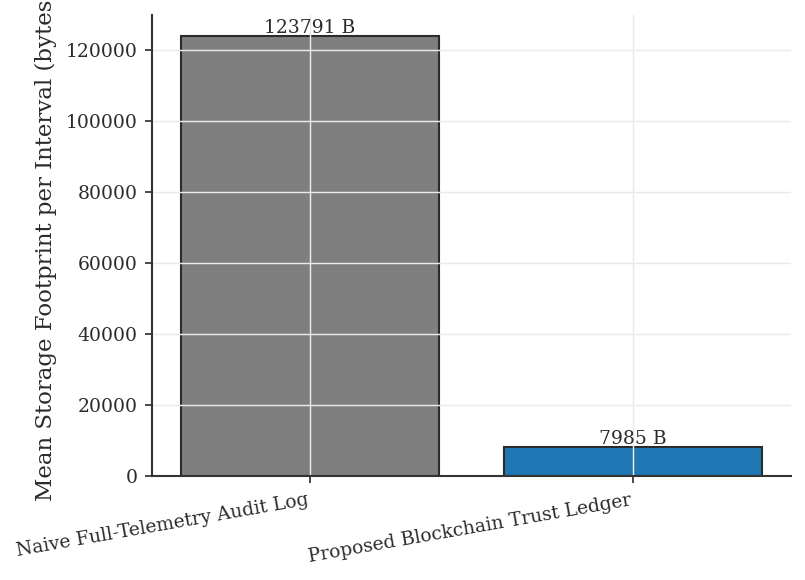

In [22]:
fig, ax = plt.subplots(figsize=(5.5, 4))
bars = ax.bar(overhead_comparison['Design'], overhead_comparison['Mean Bytes / Interval'],
              color=[NEUTRAL_GRAY, PALETTE['proposed']], edgecolor='#2B2B2B')
for b, val in zip(bars, overhead_comparison['Mean Bytes / Interval']):
    ax.text(b.get_x() + b.get_width() / 2, val, f'{val:.0f} B', ha='center', va='bottom', fontsize=9)
ax.set_ylabel('Mean Storage Footprint per Interval (bytes)')
ax.set_xticklabels(overhead_comparison['Design'], rotation=10, ha='right')
plt.tight_layout()
plt.savefig('/kaggle/working/fig_ledger_vs_naive_log_overhead.png', dpi=300)
plt.show()

## 11. Blockchain Integrity Verification

In [23]:
print("Blockchain length:", len(blockchain_ref.chain))
print("Blockchain valid (hash-chain intact):", blockchain_ref.is_valid())
print("Sample block:", vars(blockchain_ref.chain[-1]).keys())
print("Last block hash:", blockchain_ref.chain[-1].hash)

Blockchain length: 1001
Blockchain valid (hash-chain intact): True
Sample block: dict_keys(['index', 'timestamp', 'records', 'events', 'previous_hash', 'hash'])
Last block hash: 3c2295af093d4cbc799578009daad6bd450926d0beb141259c8ac2680357b165


## 12. Export Results for Manuscript

In [24]:
results.to_csv('/kaggle/working/simulation_results.csv', index=False)
summary.to_csv('/kaggle/working/comparative_summary.csv')
confusion.to_csv('/kaggle/working/detection_confusion_matrix.csv')
pd.DataFrame({'Parameter': PARAM_NAMES, 'Weight': W}).to_csv('/kaggle/working/ahp_weights.csv', index=False)
print("Artifacts saved to /kaggle/working/")

Artifacts saved to /kaggle/working/
